# External replication and final robustness (Addendum C of `docs/analysis-plan.md`)

Addendum C, including the **pre-specified predictions P1–P6**, was committed before this notebook was run.
Run notebooks 01–03 first.

- **C1** Different patients: GSE114691 (Awamleh et al. 2019), 79 villous placentas, preterm-labour controls
- **C2** FLT1 link within PE donors only, independent single-cell data
- **C3** Benjamini–Hochberg FDR across the headline tests

In [1]:
import os, sys, warnings
from pathlib import Path
from urllib.request import urlretrieve, Request, urlopen
from urllib.parse import quote
if "google.colab" in sys.modules:
    os.chdir("/content/team/notebooks")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
import patsy
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ROOT = Path(".."); EXT = ROOT / "data_external"; EXT.mkdir(exist_ok=True)
DATA_DIR = ROOT / "openbio-datathon-2026" / "track-01" / "data"
FIG_DIR = ROOT / "figures"; RES_DIR = Path("results")
gmt = {l.split("\t")[0]: l.rstrip("\n").split("\t")[2:] for l in open(EXT / "h.all.v2024.1.Hs.symbols.gmt")}
HYP, GLY = set(gmt["HALLMARK_HYPOXIA"]), set(gmt["HALLMARK_GLYCOLYSIS"])
SETS = {"hypoxia (all)": HYP, "glycolysis (all)": GLY, "shared genes": HYP & GLY,
        "hypoxia-only genes": HYP - GLY, "glycolysis-only genes": GLY - HYP}

## C1. Download GSE114691 and map transcripts to genes

In [2]:
GEO = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE114nnn/GSE114691/suppl/"
GROUP_FILES = {"control": "ControlONLY", "IUGR": "IUGRONLY", "PE": "PEONLY", "PE+IUGR": "PEIUGR"}
for f in GROUP_FILES.values():
    p = EXT / f"GSE114691_MasterCount_{f}.txt.gz"
    if not p.exists():
        urlretrieve(GEO + p.name, p)

tx2gene_path = EXT / "grch37_tx2gene.tsv"
if not tx2gene_path.exists():
    q = ('<?xml version="1.0" encoding="UTF-8"?><!DOCTYPE Query><Query virtualSchemaName="default" formatter="TSV" '
         'header="1" uniqueRows="1" datasetConfigVersion="0.6"><Dataset name="hsapiens_gene_ensembl" interface="default">'
         '<Attribute name="ensembl_transcript_id"/><Attribute name="external_gene_name"/><Attribute name="gene_biotype"/>'
         '</Dataset></Query>')
    with urlopen(Request("https://grch37.ensembl.org/biomart/martservice?query=" + quote(q))) as r:
        tx2gene_path.write_bytes(r.read())
tx2gene = pd.read_csv(tx2gene_path, sep="\t").set_index("Transcript stable ID")["Gene name"]

parts, groups = [], {}
for g, f in GROUP_FILES.items():
    d = pd.read_csv(EXT / f"GSE114691_MasterCount_{f}.txt.gz", sep="\t", index_col=0)
    d.columns = [f"{g}|{c}" for c in d.columns]
    parts.append(d)
tx = pd.concat(parts, axis=1)
print("Transcripts x samples:", tx.shape, "| non-integer values:", int((tx.values % 1 != 0).sum()))
print("Duplicate sample IDs across files:", pd.Index([c.split("|")[1] for c in tx.columns]).duplicated().sum())
mapped = tx.index.isin(tx2gene.index)
print(f"Transcripts mapped to a gene symbol: {mapped.mean():.1%}")
gene_counts = tx[mapped].groupby(tx2gene.reindex(tx.index[mapped]).values).sum().round().astype(int)
ext_meta = pd.DataFrame({"group": [c.split("|")[0] for c in gene_counts.columns]}, index=gene_counts.columns)
print(gene_counts.shape, ext_meta.group.value_counts().to_dict())

Transcripts x samples: (204940, 79) | non-integer values: 0
Duplicate sample IDs across files: 0
Transcripts mapped to a gene symbol: 100.0%
(56232, 79) {'control': 21, 'PE': 20, 'PE+IUGR': 20, 'IUGR': 18}


In [3]:
gc = gene_counts.loc[(gene_counts >= 10).sum(axis=1) >= 5]
ext_meta["pe_status"] = np.where(ext_meta.group.str.startswith("PE"), "PE", "no_PE")
dds = DeseqDataSet(counts=gc.T, metadata=ext_meta[["pe_status"]], design="~pe_status",
                   inference=DefaultInference(n_cpus=4), quiet=True)
dds.fit_size_factors(); dds.vst(use_design=False)
vst_e = pd.DataFrame(dds.layers["vst_counts"], index=gc.columns, columns=gc.index)
z_e = (vst_e - vst_e.mean()) / vst_e.std()
for k, v in SETS.items():
    print(f"{k:<22} {sum(g in z_e.columns for g in v)} of {len(v)} genes measured")
S = pd.DataFrame({k: z_e[sorted(g for g in v if g in z_e.columns)].mean(axis=1) for k, v in SETS.items()})
S.columns = ["hyp_all", "gly_all", "shared", "hyp_only", "gly_only"]
d = S.join(ext_meta)
d["grp"] = d.group.map({"control": "control", "PE": "EOPE", "PE+IUGR": "EOPEIUGR", "IUGR": "IUGR"})
d.join(vst_e[["FLT1"]]).to_csv(RES_DIR / "C1_scores_GSE114691.csv")

hypoxia (all)          183 of 200 genes measured
glycolysis (all)       188 of 200 genes measured
shared genes           62 of 65 genes measured
hypoxia-only genes     121 of 135 genes measured
glycolysis-only genes  126 of 135 genes measured


### Pre-specified predictions P1–P4

In [4]:
FORM = "{y} ~ C(grp, Treatment('control'))"
names = {g: f"C(grp, Treatment('control'))[T.{g}]" for g in ["EOPE", "EOPEIUGR", "IUGR"]}
CONTRASTS = {"EOPE vs control": {names["EOPE"]: 1}, "EOPE+IUGR vs control": {names["EOPEIUGR"]: 1},
             "IUGR-only vs control": {names["IUGR"]: 1}, "EOPE vs IUGR-only": {names["EOPE"]: 1, names["IUGR"]: -1},
             "PE (both) vs IUGR-only": {names["EOPE"]: 0.5, names["EOPEIUGR"]: 0.5, names["IUGR"]: -1}}
labels = dict(zip(S.columns, SETS.keys()))
rows = []
for y in S.columns:
    f = smf.ols(FORM.format(y=y), data=d).fit()
    for cname, w in CONTRASTS.items():
        L = np.zeros(len(f.params))
        for k, v in w.items(): L[list(f.params.index).index(k)] = v
        t = f.t_test(L); ci = t.conf_int()[0]
        p2 = float(t.pvalue); est = float(t.effect[0])
        rows.append({"score": labels[y], "contrast": cname, "estimate": est, "CI_low": ci[0], "CI_high": ci[1],
                     "std_err": float(np.ravel(t.sd)[0]), "df_resid": float(f.df_resid),
                     "p_two_sided": p2, "p_one_sided_greater": p2 / 2 if est > 0 else 1 - p2 / 2})
c1 = pd.DataFrame(rows); c1.to_csv(RES_DIR / "C1_GSE114691_contrasts.csv", index=False)
c1["txt"] = c1.estimate.round(2).astype(str) + " [" + c1.CI_low.round(2).astype(str) + ", " + c1.CI_high.round(2).astype(str) + "]"
pd.set_option("display.width", 220)
print(c1.pivot_table(index="score", columns="contrast", values="txt", aggfunc="first", sort=False).to_string())

def get(score, contrast, col):
    return c1[(c1.score == score) & (c1.contrast == contrast)][col].iloc[0]
pred = pd.DataFrame([
    {"prediction": "P1 hypoxia-only: EOPE > control", "estimate": get("hypoxia-only genes", "EOPE vs control", "estimate"),
     "p_one_sided": get("hypoxia-only genes", "EOPE vs control", "p_one_sided_greater")},
    {"prediction": "P2 hypoxia-only: PE (both) > IUGR-only", "estimate": get("hypoxia-only genes", "PE (both) vs IUGR-only", "estimate"),
     "p_one_sided": get("hypoxia-only genes", "PE (both) vs IUGR-only", "p_one_sided_greater")},
    {"prediction": "P3a shared: EOPE > control", "estimate": get("shared genes", "EOPE vs control", "estimate"),
     "p_one_sided": get("shared genes", "EOPE vs control", "p_one_sided_greater")},
    {"prediction": "P3b shared: PE (both) > IUGR-only", "estimate": get("shared genes", "PE (both) vs IUGR-only", "estimate"),
     "p_one_sided": get("shared genes", "PE (both) vs IUGR-only", "p_one_sided_greater")},
])
# P4 (corrected in Addendum E0): direct test on the per-sample difference glycolysis-only minus hypoxia-only
d["gly_minus_hyp"] = d.gly_only - d.hyp_only
f4 = smf.ols("gly_minus_hyp ~ C(grp, Treatment('control'))", data=d).fit()
t4 = f4.t_test(np.eye(len(f4.params))[list(f4.params.index).index(names["EOPE"])])
e4, p4 = float(t4.effect[0]), float(t4.pvalue)
print(f"P4 direct test: (glycolysis-only - hypoxia-only) EOPE vs control = {e4:.3f}, 95% CI {np.round(t4.conf_int()[0], 3)}, two-sided p = {p4:.2g}")
pred = pd.concat([pred, pd.DataFrame([{"prediction": "P4 glycolysis-only EOPE effect < hypoxia-only EOPE effect (direct test)",
                                       "estimate": e4, "p_one_sided": p4 / 2 if e4 < 0 else 1 - p4 / 2}])], ignore_index=True)
pred["supported"] = pred.p_one_sided < 0.05
print(pred.round(4).to_string(index=False))

contrast                   EOPE vs control EOPE+IUGR vs control  IUGR-only vs control    EOPE vs IUGR-only PE (both) vs IUGR-only
score                                                                                                                            
hypoxia (all)             0.27 [0.1, 0.43]     0.33 [0.16, 0.5]    0.16 [-0.01, 0.33]   0.11 [-0.07, 0.28]     0.14 [-0.01, 0.29]
glycolysis (all)        -0.01 [-0.13, 0.1]   0.11 [-0.01, 0.23]    -0.02 [-0.14, 0.1]   0.01 [-0.11, 0.13]     0.07 [-0.04, 0.17]
shared genes             0.37 [0.16, 0.59]     0.5 [0.29, 0.71]     0.24 [0.03, 0.46]   0.13 [-0.09, 0.35]      0.19 [-0.0, 0.39]
hypoxia-only genes       0.21 [0.06, 0.37]     0.24 [0.09, 0.4]    0.12 [-0.04, 0.27]    0.1 [-0.06, 0.26]     0.11 [-0.03, 0.25]
glycolysis-only genes  -0.2 [-0.32, -0.09]   -0.08 [-0.2, 0.03]  -0.15 [-0.27, -0.04]  -0.05 [-0.17, 0.07]      0.01 [-0.1, 0.11]
P4 direct test: (glycolysis-only - hypoxia-only) EOPE vs control = -0.417, 95% CI [-0.603 

### P5: FLT1 link within the 40 PE placentas; P6: random-gene-set null

In [5]:
pe_idx = d.index[d.pe_status == "PE"]
r5, p5 = stats.spearmanr(d.loc[pe_idx, "hyp_all"], vst_e.loc[pe_idx, "FLT1"])
print(f"P5: Spearman(hypoxia score, FLT1) within 40 PE placentas: rho = {r5:.2f}, p = {p5:.2g}   (FLT1 in set: {'FLT1' in HYP})")

X = patsy.dmatrix("C(grp, Treatment('control'))", d, return_type="dataframe")
B = np.linalg.pinv(X.values); cols = list(X.columns)
c_p1 = np.zeros(len(cols)); c_p1[cols.index(names["EOPE"])] = 1
c_p2 = np.zeros(len(cols)); c_p2[cols.index(names["EOPE"])] = .5; c_p2[cols.index(names["EOPEIUGR"])] = .5; c_p2[cols.index(names["IUGR"])] = -1
bins = pd.qcut(vst_e.mean(), 10, labels=False)
rng = np.random.default_rng(42); N = 1000
members = sorted(g for g in (HYP - GLY) if g in z_e.columns)
need = bins.loc[members].value_counts().sort_index()
pool = {b: np.array(bins.index[(bins == b) & ~bins.index.isin(members)]) for b in range(10)}
R = np.empty((len(d), N))
for i in range(N):
    pick = np.concatenate([rng.choice(pool[b], n, replace=False) for b, n in need.items()])
    R[:, i] = z_e.loc[d.index, pick].mean(axis=1).values
coefR = B @ R; obs = B @ d.hyp_only.values
p6 = {"P1": (1 + (c_p1 @ coefR >= c_p1 @ obs).sum()) / (N + 1), "P2": (1 + (c_p2 @ coefR >= c_p2 @ obs).sum()) / (N + 1)}
print("P6 empirical p (hypoxia-only vs 1,000 matched random sets):", {k: round(v, 4) for k, v in p6.items()})
pred = pd.concat([pred, pd.DataFrame([
    {"prediction": "P5 Spearman(hypoxia, FLT1) > 0 within PE (n=40)", "estimate": r5, "p_one_sided": p5 / 2 if r5 > 0 else 1 - p5 / 2, "supported": (r5 > 0) and (p5 / 2 < 0.05)},
    {"prediction": "P6a P1 beats random gene sets", "estimate": c_p1 @ obs, "p_one_sided": p6["P1"], "supported": p6["P1"] < 0.05},
    {"prediction": "P6b P2 beats random gene sets", "estimate": c_p2 @ obs, "p_one_sided": p6["P2"], "supported": p6["P2"] < 0.05}])])
pred.to_csv(RES_DIR / "C1_predictions.csv", index=False)
print(pred.round(4).to_string(index=False))

P5: Spearman(hypoxia score, FLT1) within 40 PE placentas: rho = 0.59, p = 5.6e-05   (FLT1 in set: False)


P6 empirical p (hypoxia-only vs 1,000 matched random sets): {'P1': np.float64(0.017), 'P2': np.float64(0.0889)}
                                                             prediction  estimate  p_one_sided  supported
                                        P1 hypoxia-only: EOPE > control    0.2125       0.0037       True
                                 P2 hypoxia-only: PE (both) > IUGR-only    0.1112       0.0585      False
                                             P3a shared: EOPE > control    0.3731       0.0004       True
                                      P3b shared: PE (both) > IUGR-only    0.1924       0.0256       True
P4 glycolysis-only EOPE effect < hypoxia-only EOPE effect (direct test)   -0.4174       0.0000       True
                        P5 Spearman(hypoxia, FLT1) > 0 within PE (n=40)    0.5927       0.0000       True
                                          P6a P1 beats random gene sets    0.2125       0.0170       True
                                        

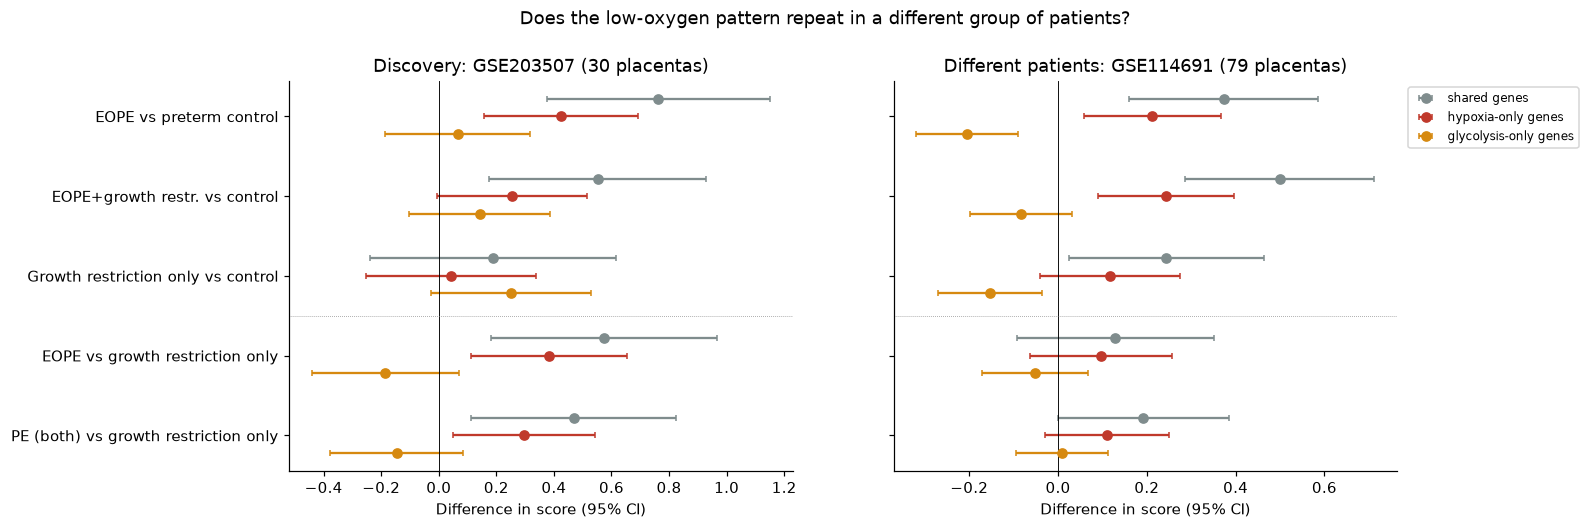

In [6]:
order = ["EOPE vs control", "EOPE+IUGR vs control", "IUGR-only vs control", "EOPE vs IUGR-only", "PE (both) vs IUGR-only"]
cols_c = {"shared genes": "#7f8c8d", "hypoxia-only genes": "#c0392b", "glycolysis-only genes": "#d68910"}
a2 = pd.read_csv(RES_DIR / "A2_A3_group_contrasts.csv"); a2 = a2[a2.se == "nonrobust"]
a2["contrast"] = a2.contrast.str.replace("iPTB", "control").str.replace("FGR-only", "IUGR-only").str.replace("EOPE+FGR", "EOPE+IUGR")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (title, tab) in zip(axes, [("Discovery: GSE203507 (30 placentas)", a2), ("Different patients: GSE114691 (79 placentas)", c1)]):
    for i, (sname, col) in enumerate(cols_c.items()):
        sub = tab[tab.score == sname].set_index("contrast").loc[order]
        y = np.arange(len(order)) + (i - 1) * 0.22
        ax.errorbar(sub.estimate, y, xerr=[sub.estimate - sub.CI_low, sub.CI_high - sub.estimate], fmt="o", c=col, label=sname, capsize=2)
    ax.axvline(0, c="k", lw=0.6); ax.axhline(2.5, c="grey", lw=0.5, ls=":"); ax.set_title(title)
    ax.set_xlabel("Difference in score (95% CI)")
axes[0].set_yticks(range(len(order))); axes[0].set_yticklabels(["EOPE vs preterm control", "EOPE+growth restr. vs control",
    "Growth restriction only vs control", "EOPE vs growth restriction only", "PE (both) vs growth restriction only"]); axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.suptitle("Does the low-oxygen pattern repeat in a different group of patients?", y=1.02)
plt.savefig(FIG_DIR / "fig9_replication_GSE114691.png", dpi=300, bbox_inches="tight"); plt.show()

## C2. FLT1 link inside PE donors only (independent single-cell data, syncytiotrophoblast)

In [7]:
pb = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv", index_col=0)
pbm = pd.read_csv(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv", index_col=0)
c2 = []
for lab, sel in [("early PE donors (n=10)", (pbm.clinical_group == "PE_early")),
                 ("all PE donors, early + late (n=17)", (pbm.pe_status == "PE"))]:
    md = pbm[(pbm.cell_class == "syncytiotrophoblast") & sel]
    c = pb[md.index]; c = c.loc[(c >= 10).sum(axis=1) >= 3]
    lc = np.log2(c / c.sum() * 1e6 + 1)
    zz = lc.sub(lc.mean(1), axis=0).div(lc.std(1).replace(0, np.nan), axis=0)
    h = zz.loc[zz.index.intersection(sorted(HYP))].mean()
    r, p = stats.spearmanr(h, lc.loc["FLT1"])
    c2.append({"set": lab, "n": len(md), "rho": r, "p": p})
c2 = pd.DataFrame(c2); c2.to_csv(RES_DIR / "C2_flt1_within_PE_pseudobulk.csv", index=False); print(c2.round(4))

                                  set   n     rho       p
0              early PE donors (n=10)  10  0.8424  0.0022
1  all PE donors, early + late (n=17)  17  0.7745  0.0003


## C3. Multiple-testing summary across headline tests (Benjamini–Hochberg)

In [8]:
A2 = pd.read_csv(RES_DIR / "A2_A3_group_contrasts.csv"); A2 = A2[A2.se == "nonrobust"].set_index(["score", "contrast"])
A1 = pd.read_csv(RES_DIR / "A1_pseudobulk.csv", index_col=0)
B2 = pd.read_csv(RES_DIR / "B2_flt1.csv").set_index("set")
B4 = pd.read_csv(RES_DIR / "B4_villi_vs_decidua.csv").set_index("tissue")
fam = [
    ("Discovery", "hypoxia-only: EOPE vs preterm control", A2.loc[("hypoxia-only genes", "EOPE vs iPTB"), "p"]),
    ("Discovery", "hypoxia-only: PE vs FGR-only", A2.loc[("hypoxia-only genes", "PE (both) vs FGR-only"), "p"]),
    ("Discovery", "shared: EOPE vs preterm control", A2.loc[("shared genes", "EOPE vs iPTB"), "p"]),
    ("Discovery", "shared: PE vs FGR-only", A2.loc[("shared genes", "PE (both) vs FGR-only"), "p"]),
    ("Discovery", "glycolysis-only: EOPE vs preterm control", A2.loc[("glycolysis-only genes", "EOPE vs iPTB"), "p"]),
    ("Discovery", "FLT1 ~ hypoxia within PE", B2.loc["within PE (n=15)", "p"]),
    ("Single-cell", "hypoxia in VCT, early PE vs control (perm)", A1.loc["villous_cytotrophoblast", "hypoxia_perm_p_two_sided"]),
    ("Single-cell", "hypoxia in STB, early PE vs control (perm)", A1.loc["syncytiotrophoblast", "hypoxia_perm_p_two_sided"]),
    ("Single-cell", "FLT1 ~ hypoxia in STB, early PE only", c2.p[0]),
    ("Decidua", "PE x tissue interaction", B4.loc["interaction (decidua - villi)", "p"]),
    ("Replication", "P1 hypoxia-only: EOPE vs control", get("hypoxia-only genes", "EOPE vs control", "p_two_sided")),
    ("Replication", "P2 hypoxia-only: PE (both) vs IUGR-only", get("hypoxia-only genes", "PE (both) vs IUGR-only", "p_two_sided")),
    ("Replication", "P3a shared: EOPE vs control", get("shared genes", "EOPE vs control", "p_two_sided")),
    ("Replication", "P3b shared: PE (both) vs IUGR-only", get("shared genes", "PE (both) vs IUGR-only", "p_two_sided")),
    ("Replication", "P4 glycolysis-only minus hypoxia-only: EOPE vs control", p4),
    ("Replication", "P5 FLT1 ~ hypoxia within PE (n=40)", p5),
]
# Addendum E0: one BH family of two-sided parametric p-values; empirical random-set p-values reported separately
c3 = pd.DataFrame(fam, columns=["data", "test", "p_two_sided"])
c3["q_BH"] = multipletests(c3.p_two_sided, method="fdr_bh")[1]
print("Empirical random-gene-set p-values (one-sided, not in BH family):", {k: round(v, 4) for k, v in p6.items()})
c3.to_csv(RES_DIR / "C3_fdr_summary.csv", index=False)
print(c3.round(4).to_string(index=False))

Empirical random-gene-set p-values (one-sided, not in BH family): {'P1': np.float64(0.017), 'P2': np.float64(0.0889)}
       data                                                   test  p_two_sided   q_BH
  Discovery                  hypoxia-only: EOPE vs preterm control       0.0036 0.0082
  Discovery                           hypoxia-only: PE vs FGR-only       0.0206 0.0330
  Discovery                        shared: EOPE vs preterm control       0.0006 0.0025
  Discovery                                 shared: PE vs FGR-only       0.0127 0.0227
  Discovery               glycolysis-only: EOPE vs preterm control       0.5911 0.5911
  Discovery                               FLT1 ~ hypoxia within PE       0.0006 0.0025
Single-cell             hypoxia in VCT, early PE vs control (perm)       0.1503 0.1718
Single-cell             hypoxia in STB, early PE vs control (perm)       0.0804 0.1072
Single-cell                   FLT1 ~ hypoxia in STB, early PE only       0.0022 0.0059
    Decidua 